## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

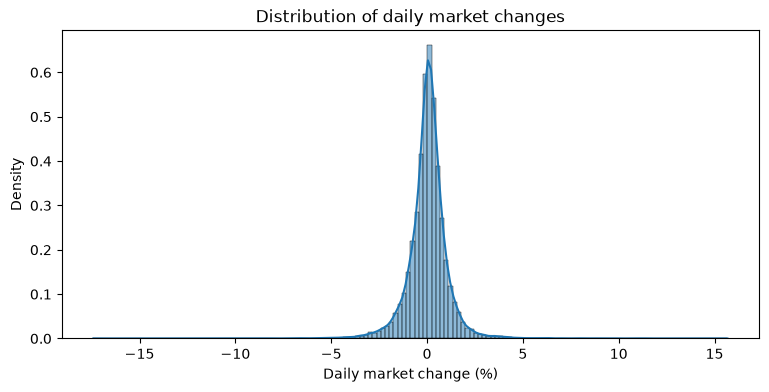

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

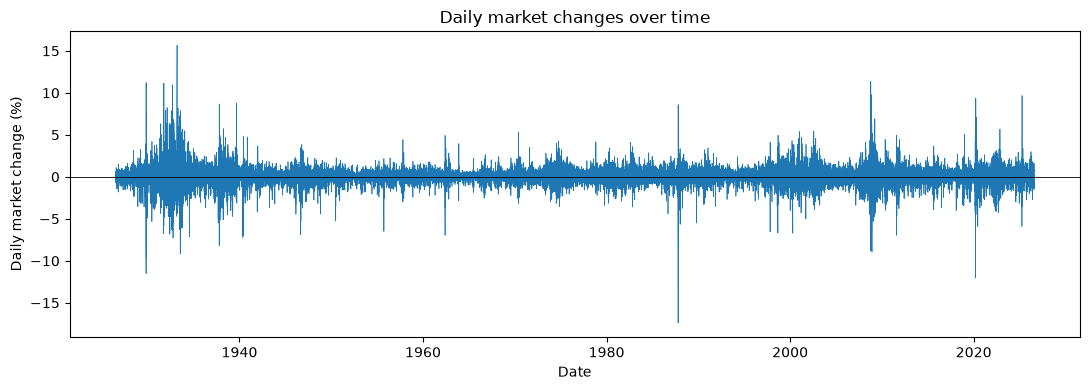

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [4]:
df['y_t'] = 'Down' 
df.loc[df['market_return_pct'] > 0, 'y_t'] = 'Up'

df['y_tp1'] = df['y_t'].shift(-1)
df['r_tp1'] = df['market_return_pct'].shift(1)

pairs = df.dropna(subset=['y_tp1']).copy()
len(pairs)
pairs[['date', 'market_return_pct', 'y_t', 'y_tp1']].head()

,date,market_return_pct,y_t,y_tp1
0,1926-07-01,0.10,Up,Up
1,1926-07-02,0.46,Up,Up
2,1926-07-06,0.18,Up,Up
3,1926-07-07,0.10,Up,Up
4,1926-07-08,0.23,Up,Down


In [5]:
joint_counts = pd.crosstab(pairs['y_t'], pairs['y_tp1'], margins=True, margins_name='All')
joint_counts

y_tp1,Down,Up,All
y_t,,,
Down,5909,5999,11908
Up,5999,8388,14387
All,11908,14387,26295


In [6]:
joint_pmf = joint_counts / joint_counts.loc['All', 'All']
joint_pmf

y_tp1,Down,Up,All
y_t,,,
Down,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


In [7]:
cond = pd.crosstab(pairs['y_t'], pairs['y_tp1'], normalize='index')
cond

y_tp1,Down,Up
y_t,,
Down,0.496221,0.503779
Up,0.416974,0.583026


Are up transitions more or less common than down transitions? 
* in the joint PMF we see that Up is more common at 54% of the data compared to down transitions at 45%
Are you more likely to transition to an Up day from a Down or Up day?
* you are more likely to transition to an Up day from an Up day in the conditional PMF .58 for Up/Up

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [8]:
bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf]
labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']

df['y_t'] = pd.cut(df['market_return_pct'], bins=bins, labels=labels, right = True)
df['y_tp1'] = df['y_t'].shift(-1)
df['r_tp1'] = df['market_return_pct'].shift(-1)

pairs = df.dropna(subset=['y_tp1']).copy()
pairs

,date,year,month,month_start,trading_day_of_month,mkt_excess_return_pct,risk_free_return_pct,market_return_pct,absolute_market_return_pct,y_t,y_tp1,r_tp1
0,1926-07-01,1926,7,1926-07-01,1,0.09,0.01,0.10,0.10,Near zero,Small gain,0.46
1,1926-07-02,1926,7,1926-07-01,2,0.45,0.01,0.46,0.46,Small gain,Small gain,0.18
2,1926-07-06,1926,7,1926-07-01,3,0.17,0.01,0.18,0.18,Small gain,Near zero,0.10
3,1926-07-07,1926,7,1926-07-01,4,0.09,0.01,0.10,0.10,Near zero,Small gain,0.23
4,1926-07-08,1926,7,1926-07-01,5,0.22,0.01,0.23,0.23,Small gain,Small loss,-0.70
...,...,...,...,...,...,...,...,...,...,...,...,...
26290,2026-07-24,2026,7,2026-07-01,17,0.00,0.02,0.02,0.02,Near zero,Small gain,0.17
26291,2026-07-27,2026,7,2026-07-01,18,0.15,0.02,0.17,0.17,Small gain,Small gain,0.29
26292,2026-07-28,2026,7,2026-07-01,19,0.27,0.02,0.29,0.29,Small gain,Large loss,-1.50
26293,2026-07-29,2026,7,2026-07-01,20,-1.52,0.02,-1.50,1.50,Large loss,Large gain,1.61


In [9]:
pairs['y_t'].value_counts().sort_index()

y_t
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9784
Large gain    2859
Name: count, dtype: int64

How many days fall into each of the five bins? Which are the most or least common?
* Large loss    2759
* Small loss    7452
* Near zero     3441
* Small gain    9784
* Large gain    2859

* Most common : Small gain
* Least common : Large loss, large gain is close by

In [10]:
joint_counts = pd.crosstab(pairs['y_t'], pairs['y_tp1'], margins=True, margins_name='All')
joint_counts

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,561,715,238,731,514,2759
Small loss,932,2331,898,2571,720,7452
Near zero,245,1104,551,1297,244,3441
Small gain,657,2631,1447,4192,857,9784
Large gain,364,671,306,994,524,2859
All,2759,7452,3440,9785,2859,26295


In [11]:
joint_pmf = joint_counts / joint_counts.loc['All','All']
joint_pmf

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


Compute the joint PMF and marginals. Which transitions are most likely to occur? 
* small gain to small gain is the most likely transition

In [12]:
cond = pd.crosstab(pairs['y_t'], pairs['y_tp1'], normalize='index')
cond

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


For each current state, which two future states are the most likely? 
* Large loss: Small gain (0.265), Small loss (0.259)
* Small loss: Small gain (0.345), Small loss (0.313)
* Near zero: Small gain (0.377), Small loss (0.321)
* Small gain: Small gain (0.428), Small loss (0.269)
* Large gain: Small gain (0.348), Small loss (0.235)

Subjectively, how close is each row to a uniform mass function with probability .2 over each transition?
* Large loss: fairly far from .2, large loss is AT .2, large gain is close at .19
* Small loss: not close to .2, 
* Near zero: not close to .2
* Small gain: all but small loss/ near zero is very far from .2
* Large gain: small loss and large gain are close to .2 but the others aren't

Is it relatively easy or difficult to predict the next state?
* its difficult the strongest signal is only .43 and thats for small gain to small gain. The others are weaker, so overall predictability is difficult.

For each state, compute the conditional expectation of tomorrow's `market_return_pct`. 

In [13]:
desc = pairs.groupby('y_t')['r_tp1'].describe()[['min', 'mean', 'max', 'std']]
desc

,min,mean,max,std
y_t,,,,
Large loss,-17.41,-0.038311,11.22,1.720570
Small loss,-11.23,-0.043814,11.36,1.009529
Near zero,-8.19,0.015013,5.49,0.826054
Small gain,-8.25,0.106810,8.67,0.832186
Large gain,-12.00,0.163092,15.67,1.384086


Given the current state, what are the expected percent returns for tomorrow?  
* After Large loss: about −0.04 %
* After Small loss: about −0.04 %
* After Near zero: about +0.02 %
* After Small gain: about +0.11 %
* After Large gain: about +0.16 %

How do the min and max values for tomorrow vary across states?
* The largest moves both negative and positive are after a large loss/gain. Which implies volatility.

Which states have the highest standard deviation for tomorrow's percent returns? 
* It is again Large loss/gain. The other bins are all below 1.01.

Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 
* Volatility shows the momentum, an object in motion tends to stay in motion. So, we see big days follow big days and slow stagnant days followed by it. 

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [14]:
df['y_t']   = pd.qcut(df['market_return_pct'], q=21, labels=False, duplicates='drop')
df['y_tp1'] = df['y_t'].shift(-1)
df['r_tp1'] = df['market_return_pct'].shift(-1)

pairs = df.dropna(subset=['y_tp1']).copy()
pairs[['market_return_pct', 'y_t', 'y_tp1']].head()

,market_return_pct,y_t,y_tp1
0,0.10,10,15.0
1,0.46,15,11.0
2,0.18,11,10.0
3,0.10,10,12.0
4,0.23,12,3.0


- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.

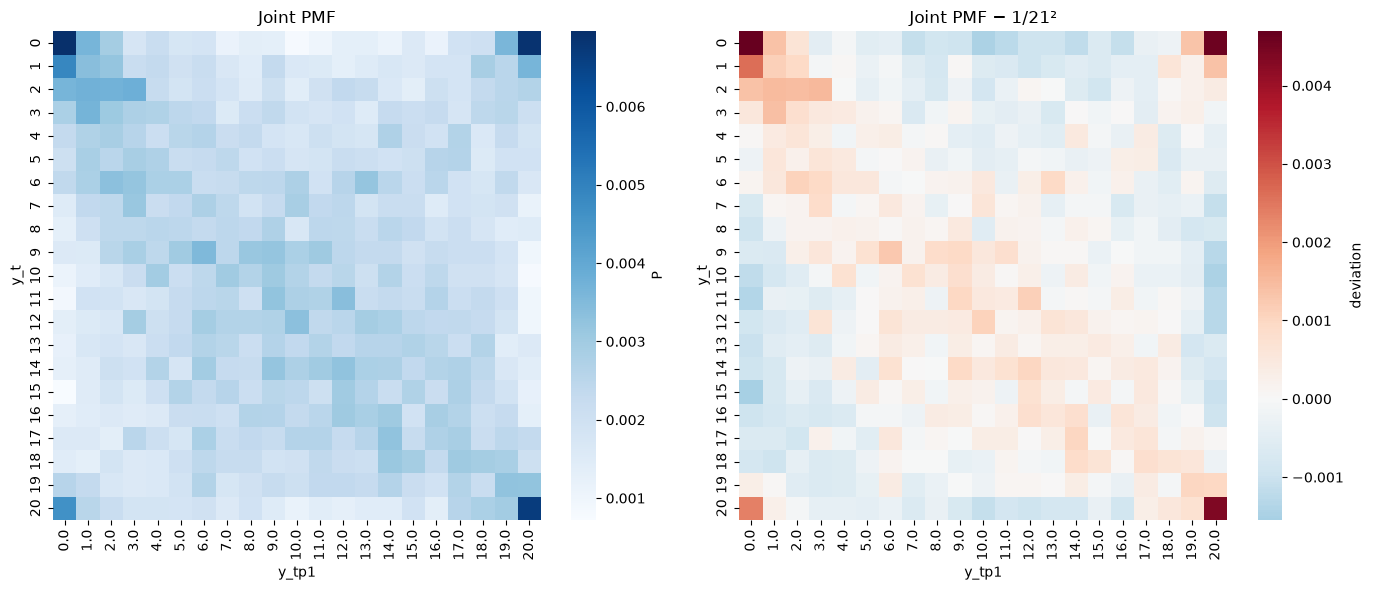

In [18]:
n_bins = pairs['y_t'].nunique()          # should be 21
joint  = pd.crosstab(pairs['y_t'], pairs['y_tp1'], normalize='all')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(joint, ax=axes[0], cmap='Blues', cbar_kws={'label': 'P'})
axes[0].set_title('Joint PMF')

sns.heatmap(joint - 1/n_bins**2, ax=axes[1], cmap='RdBu_r', center=0,
            cbar_kws={'label': 'deviation'})
axes[1].set_title('Joint PMF − 1/21²')

plt.tight_layout()
plt.show()

Do you see any obvious patterns?
* there is some soft diagonal X in play, but the obvious 'heat' is in the corners. This sticks with the same pattern we have been discussing above.

Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
* there is a similar soft diagonal X and the 'heat' is still in the corners.

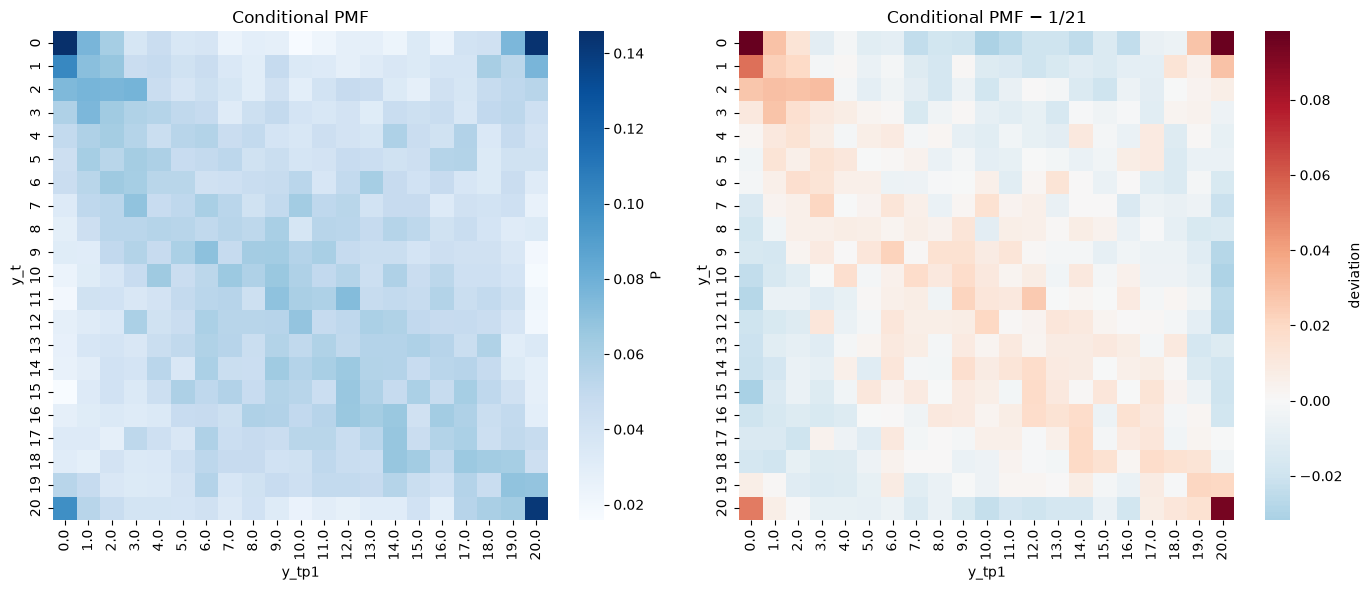

In [20]:
cond = pd.crosstab(pairs['y_t'], pairs['y_tp1'], normalize='index')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(cond, ax=axes[0], cmap='Blues', cbar_kws={'label': 'P'})
axes[0].set_title('Conditional PMF')

sns.heatmap(cond - 1/n_bins, ax=axes[1], cmap='RdBu_r', center=0,
            cbar_kws={'label': 'deviation'})
axes[1].set_title('Conditional PMF − 1/21')

plt.tight_layout()
plt.show()

For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
* the mean is very tight around zero, which matches the daily distribution plot at the very top of the lab. 
* min and max have a very mirrored appearance with the edges peaking/dropping. suggesting that the biggest next-day moves follow the extremes. 

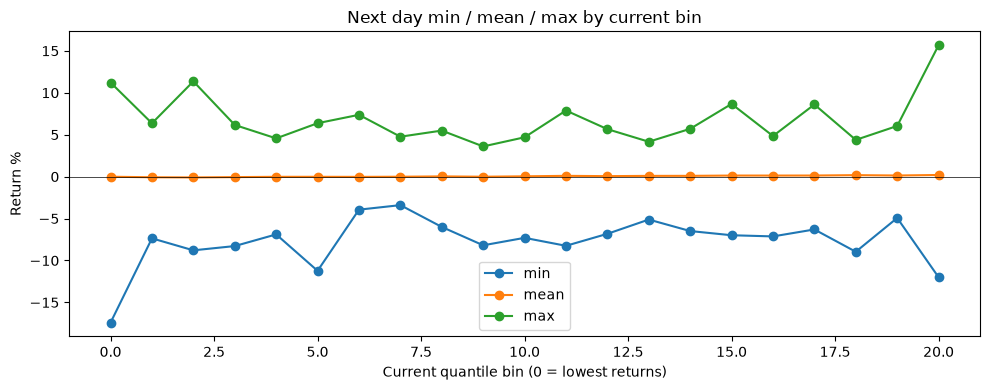

In [21]:
stats = pairs.groupby('y_t')['r_tp1'].agg(['min', 'mean', 'max'])

fig, ax = plt.subplots(figsize=(10, 4))
bins = stats.index

ax.plot(bins, stats['min'],  marker='o', label='min')
ax.plot(bins, stats['mean'], marker='o', label='mean')
ax.plot(bins, stats['max'],  marker='o', label='max')
ax.axhline(0, color='k', lw=0.5)
ax.legend()
ax.set_title('Next day min / mean / max by current bin')
ax.set_xlabel('Current quantile bin (0 = lowest returns)')
ax.set_ylabel('Return %')
plt.tight_layout()
plt.show()

For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain.
* the obvious pattern is the U-shape. the standard deviation is highest in the extreme edge cases vs the lower std in the mid cases. This follows the idea of momentum in the volatility we have seen previously.

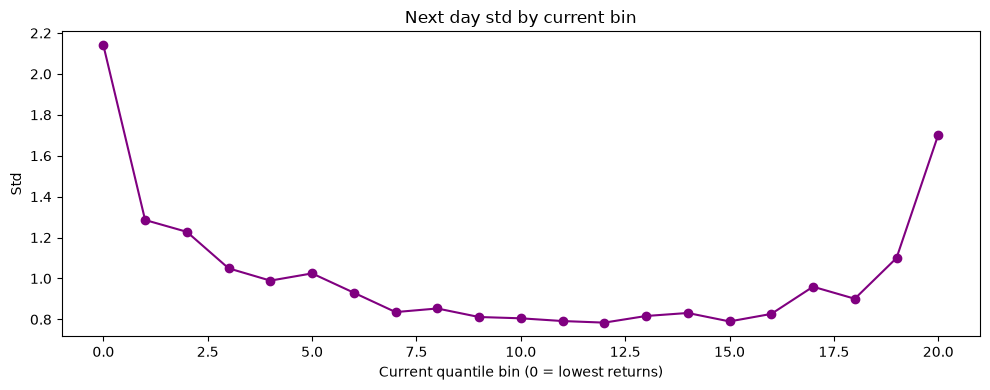

In [22]:
stats = pairs.groupby('y_t')['r_tp1'].agg(['std'])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(stats.index, stats['std'], marker='o', color='purple')
ax.set_title('Next day std by current bin')
ax.set_xlabel('Current quantile bin (0 = lowest returns)')
ax.set_ylabel('Std')
plt.tight_layout()
plt.show()

How easy is it to predict the market?
* Super easy (slight sarcasm), obviously its going to be volatile in the short term. In the long run we have seen a positive return. The answer you're looking for is that its difficult, but that's with short term views. Buy the dip.